## 1. Setup & Import

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    RocCurveDisplay,          
) 
from sklearn.model_selection import cross_val_score, StratifiedKFold
import joblib


sns.set_style("whitegrid")
pd.set_option("display.float_format", "{:.2f}".format)

## 2. Data Loading and Initial Inspection

In [2]:
df = pd.read_csv('../data/WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.describe(include='object').T

,count,unique,top,freq
customerID,7043,7043,3186-AJIEK,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


In [8]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [9]:
print(df['TotalCharges'].isnull().sum())

11


In [10]:
df = df.dropna(subset=['TotalCharges'])
print(df['TotalCharges'].count())

7032


In [11]:
df['SeniorCitizen'] = df['SeniorCitizen'].map({0:'No', 1:'Yes'})
print(df['SeniorCitizen'].unique())

['No' 'Yes']


In [12]:
df.drop(columns=['customerID'], inplace=True)

In [13]:
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

In [14]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


Churn
0   0.73
1   0.27
Name: proportion, dtype: float64


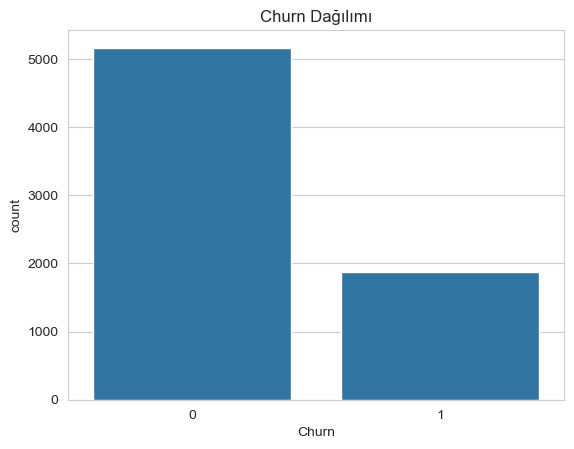

In [15]:
print(df["Churn"].value_counts(normalize=True))
sns.countplot(x='Churn', data=df)
plt.title("Churn Dağılımı")
plt.show()

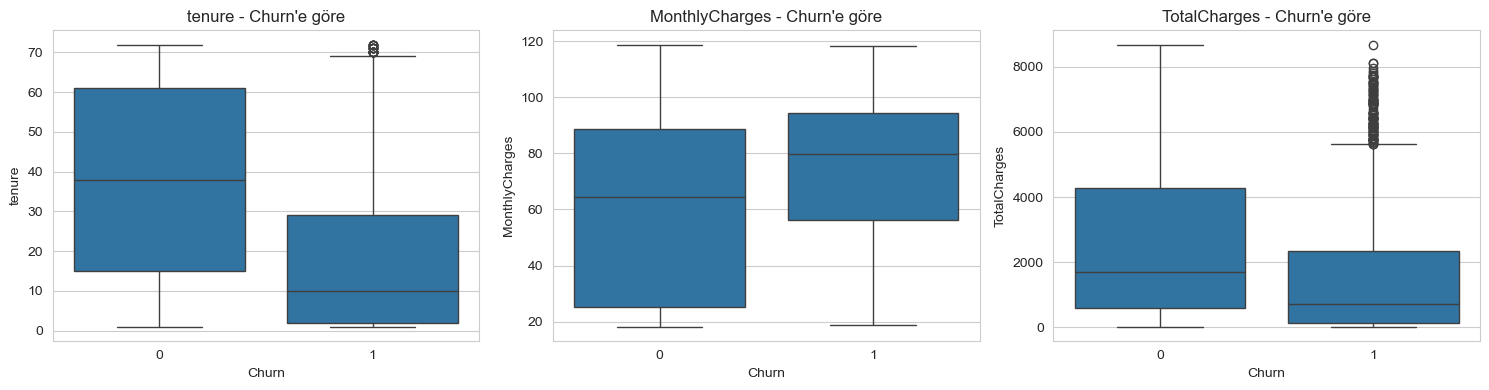

In [16]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i in range(len(num_cols)):
    col = num_cols[i]
    sns.boxplot(x="Churn", y=col, data=df, ax=axes[i])
    axes[i].set_title(f"{col} - Churn'e göre")
plt.tight_layout()
plt.show()

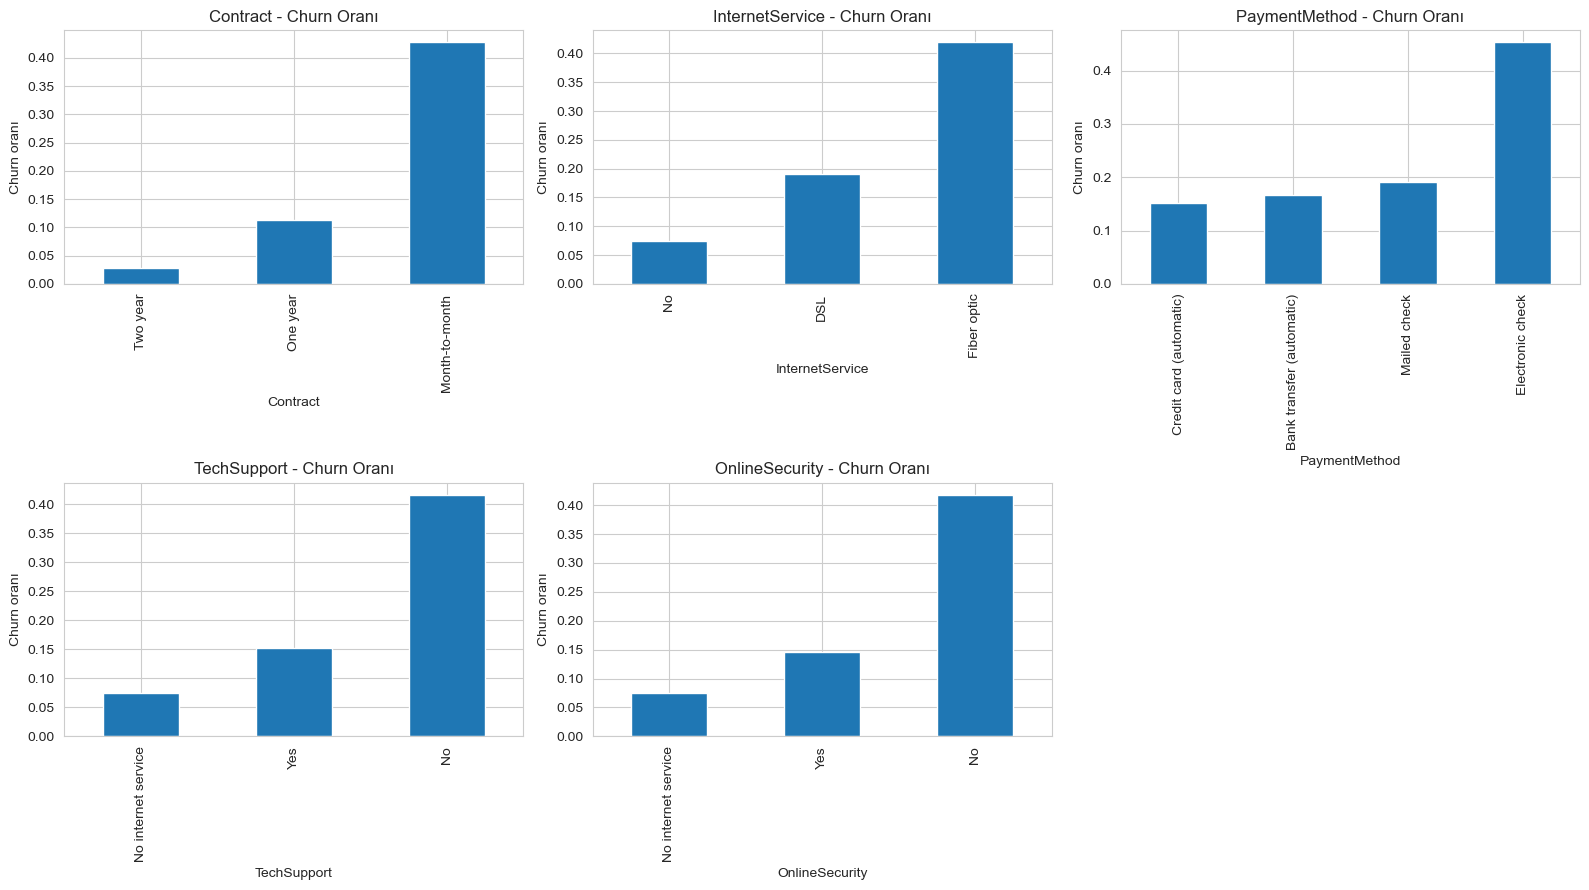

In [17]:
cat_cols = ["Contract", "InternetService", "PaymentMethod",
            "TechSupport", "OnlineSecurity"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flat
for i in range(len(cat_cols)):
    col = cat_cols[i]
    df.groupby(col)["Churn"].mean().sort_values().plot(kind="bar", ax=axes[i])
    axes[i].set_title(f"{col} - Churn Oranı")
    axes[i].set_ylabel("Churn oranı")
axes[5].axis("off")   # 6. boş kareyi gizle (5 grafik, 6 kare)
plt.tight_layout()
plt.show()

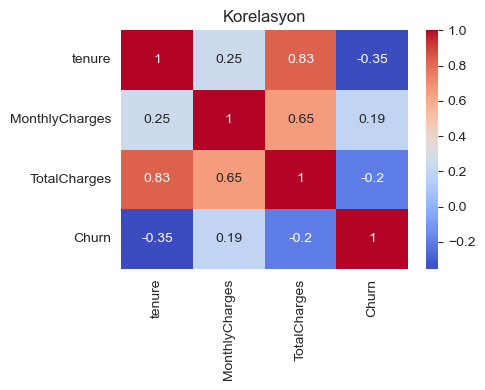

In [18]:
plt.figure(figsize=(5, 4))
sns.heatmap(df[num_cols + ["Churn"]].corr(), annot=True, cmap="coolwarm")
plt.title("Korelasyon")
plt.tight_layout()
plt.show()

In [19]:
X = df.drop(columns=['Churn'])
y = df['Churn']

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [21]:
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(include="object").columns.tolist()

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

In [22]:
logreg = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000)),
])

logreg.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'SeniorCitizen',
                                                   'Partner', 'Dependents',
                                                   'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [23]:
# --- 10. Random Forest ---
rf = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(class_weight="balanced", random_state=42)),
])

rf.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'SeniorCitizen',
                                                   'Partner', 'Dependents',
                                                   'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced',
                                        random_state=42))])

In [24]:
# --- 10. Gradient Boosting ---
gb = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", GradientBoostingClassifier(random_state=42)),
])

gb.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'SeniorCitizen',
                                                   'Partner', 'Dependents',
                                                   'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('model', GradientBoostingClassifier(random_state=42))])

In [25]:
# --- 11. Üç modeli tek tabloda karşılaştır ---
models = {
    "Logistic Regression": logreg,
    "Random Forest": rf,
    "Gradient Boosting": gb,
}

results = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    print(f"=== {name} ===")
    print("Confusion matrix:")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred))

    report = classification_report(y_test, y_pred, output_dict=True)
    results.append({
        "Model": name,
        "Recall (churn)": report["1"]["recall"],
        "Precision (churn)": report["1"]["precision"],
        "F1 (churn)": report["1"]["f1-score"],
        "ROC-AUC": roc_auc_score(y_test, y_proba),
    })

comparison = pd.DataFrame(results).round(3)
print(comparison)

=== Logistic Regression ===
Confusion matrix:
[[723 310]
 [ 76 298]]
              precision    recall  f1-score   support

           0       0.90      0.70      0.79      1033
           1       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407

=== Random Forest ===
Confusion matrix:
[[921 112]
 [184 190]]
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1033
           1       0.63      0.51      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407

=== Gradient Boosting ===
Confusion matrix:
[[923 110]
 [176 198]]
              precision    recall  f1-score   support

           0       0.84      0.89      0.87      1033
           1       0.64      0.53     

In [26]:
# --- 12. Cross-validation (en iyi modelde) ---
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(gb, X, y, cv=cv, scoring="roc_auc")

print("CV ROC-AUC skorları:", scores.round(3))
print("Ortalama:", scores.mean().round(3), "Std:", scores.std().round(3))

CV ROC-AUC skorları: [0.848 0.855 0.845 0.844 0.841]
Ortalama: 0.846 Std: 0.005


In [27]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(logreg, X, y, cv=cv, scoring="roc_auc")

print("CV ROC-AUC skorları:", scores.round(3))
print("Ortalama:", scores.mean().round(3), "Std:", scores.std().round(3))

CV ROC-AUC skorları: [0.847 0.848 0.845 0.844 0.84 ]
Ortalama: 0.845 Std: 0.003


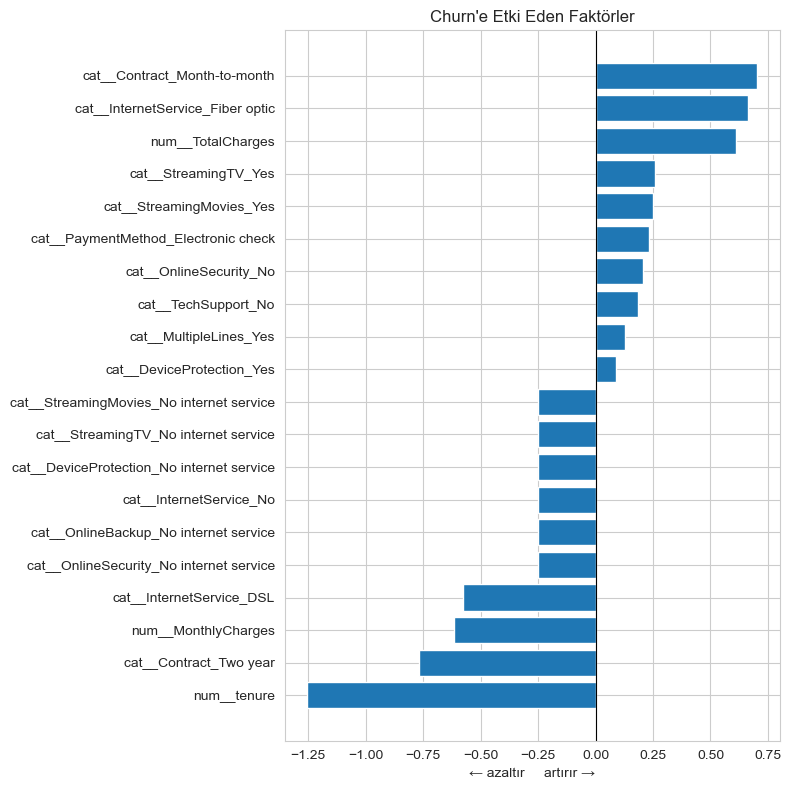

In [28]:
feature_names = logreg.named_steps["preprocessing"].get_feature_names_out()
coefs = logreg.named_steps["model"].coef_[0]

coef_df = pd.DataFrame({"feature": feature_names, "coef": coefs}).sort_values("coef")

# En etkili 10 artıran + 10 azaltan
top = pd.concat([coef_df.head(10), coef_df.tail(10)])

plt.figure(figsize=(8, 8))
plt.barh(top["feature"], top["coef"])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Churn'e Etki Eden Faktörler")
plt.xlabel("← azaltır     artırır →")
plt.tight_layout()
plt.show()

In [29]:
joblib.dump(logreg, "churn_model.pkl")

['churn_model.pkl']

In [30]:
test_model = joblib.load("churn_model.pkl")
print(test_model.predict(X_test[:5]))

[0 1 0 0 0]
